In [1]:
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.patches as patches
import pickle
import sys
sys.path.insert(0,'../src/')



from utils import *
from multiply_connected_pipe import *
from pipe_system import PipeSystem
from abstract_pipe import *
from curve import *

# Set up plotting parameters
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12


#### load pipe

In [2]:
import pickle

with open('pipe.pkl', 'rb') as f:
    cross, T = pickle.load(f)

#### assembling the pipes

In [9]:
def condition_number(n_rep_x,n_rep_y):

    middle_pipes = [RealPipe(cross,20*i,20*j,0) for i in range(n_rep_x) for j in range(1,n_rep_y-1)]
    bottom_pipes = [RealPipe(T,20*i,20*0,np.pi) for i in range(n_rep_x)]
    top_pipes = [RealPipe(T,20*i,20*(n_rep_y-1),0) for i in range(n_rep_x)]

    pipes = top_pipes + middle_pipes + bottom_pipes
    
    
    flows = []
    for ip,p in enumerate(pipes):
        for iflow in range(p.n_flows):
            flows.append((ip,iflow))
    flows = list(enumerate(flows))
    flows_idx2flow = dict(flows)
    flow2flows_idx = {flow:idx for idx,flow in flows}

    from itertools import product
    
    
    _traverse = dict()

    for ip,p in enumerate(pipes):
        for il,l in enumerate(p.lets):
            _traverse[(ip,il)] = (p,l)
    _nodes = []


    # internal nodes
    for ((ip1,il1), (p1,l1)),((ip2,il2), (p2,l2)) in product(_traverse.items(),repeat=2):
        if ip1>=ip2: 
            continue
        if l1.almost_match(l2):
            # create an internal node
            _nodes.append({
                'node_type': 'internal',
                'let0': (ip1,il1),
                'let1': (ip2,il2),
                'pos': (l1.x,l1.y),
            })
            
    # boundary nodes
    for ((ip,il), (p,l)) in _traverse.items():
        pos = np.array([l.x,l.y])
        dist = np.min([np.linalg.norm(pos - n['pos'])  for n in _nodes])
        if dist < 1e-6:
            continue
        
        _nodes.append({
            'node_type': 'boundary',
            'let': (ip,il),
            'pos': (l.x,l.y),
        })
    # creating the flux equations at each node
    n_flows = len(flows)
    flux_equations = []
    for n in _nodes:
        if n['node_type'] != 'internal':
            continue
        
        let0 = n['let0']
        let1 = n['let1']
        
        equation = np.zeros(n_flows)
        p0,l0 = let0
        p1,l1 = let1
        
        for i, (ip,iflow) in flows:
            
            '''
            this flow is from the 0-th let to the i-flow-1 -th let in the pipe ip. 
            '''
            if ip == p0 and l0 == iflow + 1:
                equation[i] = -1 # flowing into the node
            if ip == p1 and l1 == iflow + 1:
                equation[i] = -1 # flowing into the node
            if ip == p0 and l0 == 0:
                equation[i] = 1 # this flow flows out of the node
            if ip == p1 and l1 == 0:
                equation[i] = 1 # this flow flows out of the node
            
        
        flux_equations.append(equation)
    flux_equations=np.array(flux_equations)
    
    def one_hot(index, size):
        vec = np.zeros(size)
        vec[index] = 1
        return vec
        
    # create the graphs with all the edges
    edges = []

    def fn_lets(node):
        if node['node_type'] == 'internal':
            return [node['let0'],node['let1']]
        else:
            return [node['let']]
        
    for ip,p in enumerate(pipes):
        for iflow in range(p.n_flows):
            
            start_let = (ip,0)    
            start_node_idx = [inode for inode,n in enumerate(_nodes) if start_let in fn_lets(n)][0]
            end_let = (ip,iflow+1)
            end_node_idx = [inode for inode,n in enumerate(_nodes) if end_let in fn_lets(n)][0]
            
            edges.append((start_node_idx,end_node_idx))
    def fn_n2l(n):
        if n['node_type'] == 'internal':
            return [n['let0'],n['let1']]
        else:
            return [n['let']]

    edges2pressure_drop = {}

    for e in edges:
        n0 = _nodes[e[0]]
        n1 = _nodes[e[1]]
        
        l0 = fn_n2l(n0)
        l1 = fn_n2l(n1)
        
        cap = [(ll,lll) for ll, lll in product(l0,l1) if ll[0] == lll[0]]
        assert len(cap) == 1
        
        cap = cap[0]
        
        p = cap[0][0]
        l0 = cap[0][1]
        l1 = cap[1][1]
        
        pd = pipes[p].pressure_drops
        
        if l0 == 0:
            pd = pd[:,l1-1]
        elif l1 == 0:
            pd = -pd[:,l0-1]
        else: 
            pd = pd[:,l1-1] - pd[:,l0-1]
        
        pdf = np.zeros(len(flows))
        
        idx = [i for i,(j,k) in flows if j==p]
        
        pdf[idx] = pd
        
        edges2pressure_drop[e] = pdf
        
        
        reverse_e = (e[1],e[0])
        edges2pressure_drop[reverse_e] = -pdf
    import networkx as nx

    g = nx.Graph()
    g.add_nodes_from(range(len(_nodes)))
    g.add_edges_from(edges)

    cycles = nx.cycle_basis(g)


    # pressure drop equations

    pressure_drop_equations = []
    for c in cycles:
        eq = np.zeros(len(flows))
        for e in zip(c,c[1:]+[c[0]]):
            eq += edges2pressure_drop[e]
        
        pressure_drop_equations.append(eq)

    pressure_drop_equations = np.vstack(pressure_drop_equations)
    
    
    laws = np.vstack([pressure_drop_equations,flux_equations])
        
    f_equations = []
    boundary_lets = [n for n in _nodes if n['node_type'] == 'boundary']

    for n in boundary_lets[:-1]:
        p,l = n['let']
        
        equation = np.zeros(n_flows)
        
        if l == 0:
            
            flow_idx = [i for i,(j,k) in flows if j == p]
            equation[flow_idx] = 1
            # flow in
            
        else:
            flow_idx = [i for i,(j,k) in flows if (j,k) == (p,l-1)]
            assert len(flow_idx) == 1
            flow_idx = flow_idx[0]
            equation[flow_idx] = -1
            # flow out
            
        f_equations.append(equation)

    A = np.vstack([f_equations,laws])
    
    return np.linalg.cond(A)


In [10]:
from tqdm import tqdm

In [11]:
xs = np.arange(5,50,dtype=int)
ys = []

for n in tqdm(xs):
    ys.append(condition_number(n,n))

100%|██████████| 45/45 [55:57<00:00, 74.60s/it] 


In [19]:
import pickle

with open('condition_number.pkl','wb') as f:
    pickle.dump((xs,ys),f)
    

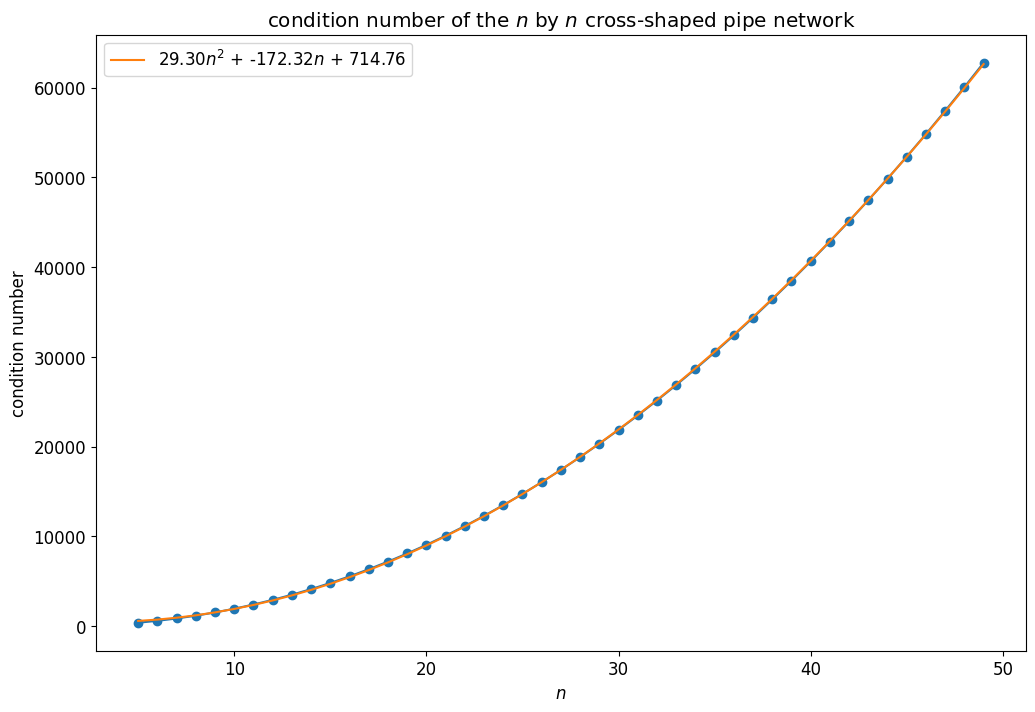

In [22]:
plt.plot(xs,ys,marker='o')
plt.ylabel('condition number')
plt.xlabel('$n$')
plt.title('condition number of the $n$ by $n$ cross-shaped pipe network')

coef = np.polyfit(xs,ys,2)
vand = np.vander(xs,3)
plt.plot(xs,vand@coef,label=f'{coef[0]:.2f}$n^2$ + {coef[1]:.2f}$n$ + {coef[2]:.2f}')
plt.legend()
plt.savefig('condition_number.png')